## Configuration et prétraitement des données (Veri Hazırlama ve Ön İşleme)

#### Cellule 1 : Import des librairies (Kütüphanelerin içe aktarılması)

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

#### Cellule 2 : Charger les données (Veri setinin yüklenmesi)

In [2]:
spam = pd.read_csv("data/spam.csv")
spam.head()

,crl.tot,dollar,bang,money,n000,make,yesno
0,278,0.000,0.778,0.00,0.00,0.00,y
1,1028,0.180,0.372,0.43,0.43,0.21,y
2,2259,0.184,0.276,0.06,1.16,0.06,y
3,191,0.000,0.137,0.00,0.00,0.00,y
4,191,0.000,0.135,0.00,0.00,0.00,y


#### Cellule 3 : Infos sur les colonnes (Sütun bilgileri)

In [3]:
spam.info()

<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crl.tot  4601 non-null   int64  
 1   dollar   4601 non-null   float64
 2   bang     4601 non-null   float64
 3   money    4601 non-null   float64
 4   n000     4601 non-null   float64
 5   make     4601 non-null   float64
 6   yesno    4601 non-null   str    
dtypes: float64(5), int64(1), str(1)
memory usage: 256.2 KB


#### cellule 4 : statistiques (İstatistikler)

In [4]:
spam.describe()

,crl.tot,dollar,bang,money,n000,make
count,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000
mean,283.289285,0.075811,0.269071,0.094269,0.101645,0.104553
std,606.347851,0.245882,0.815672,0.442636,0.350286,0.305358
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,266.000000,0.052000,0.315000,0.000000,0.000000,0.000000
max,15841.000000,6.003000,32.478000,12.500000,5.450000,4.540000


#### Cellule 5 : Encoder la cible (Hedef değişkenin kodlanması)

In [5]:
categorical_columns = spam.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
print(categorical_columns)

['yesno']


#### Cellule 6 : Transformer y/n en 1/0 (y/n değerlerinin 1/0'a dönüştürülmesi)

In [6]:
label_encoders = {col: LabelEncoder() for col in categorical_columns}
for col in categorical_columns:
    spam[col] = label_encoders[col].fit_transform(spam[col])

spam['yesno'].value_counts()

yesno
0    2788
1    1813
Name: count, dtype: int64

#### cellule 7 : séparer les variables x de la cible y (Özellikler (X) ve hedef (y) ayrımı)

In [7]:
X = spam.drop('yesno', axis=1)
y = spam['yesno']

print(X.shape)
print(y.shape)

(4601, 6)
(4601,)


#### Cellule 8 : Séparer en entraînement et en test (Eğitim ve test verisine ayırma)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(3680, 6) (921, 6)


#### Cellule 9 : La PCA (réduction à 2 dimensions) (Boyut indirgeme (PCA))

In [9]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print(X_train_pca.shape)

(3680, 2)


#### Cellule 10 : très utile pour la question 3, Açıklanan varyans ve PCA bileşenleri

In [10]:
print(pca.explained_variance_ratio_)
print(pca.components_)

[9.99996219e-01 2.28286897e-06]
[[ 9.99999982e-01  1.01104946e-04  5.99961571e-05  6.87388970e-05
   1.19235755e-04  5.05387319e-05]
 [-7.11100148e-05  3.98161048e-02  9.97865998e-01  3.48062226e-02
   3.08202587e-02  2.27323683e-02]]


## Étape 2 : Entraînement du modèle et visualisation des limites décisionnelles (Model Eğitimi ve Karar Sınırı)

#### cellule 1 : import des l'arbre de décision et de matplotlib (Karar ağacı kütüphanesinin içe aktarılması)

In [11]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

#### cellule 2 : entrainer l'arbre de décision (Karar ağacı modelinin eğitilmesi)

In [12]:
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train_pca, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### cellule 3 : fonction decisionplot (decisionplot fonksiyonu) 

In [13]:
# Implement the decisionplot function (as provided in the lecture content)
# Add the decisionplot function here

def decisionplot(model, X, y):
    # 1. Limites du graphique (un peu plus large que les données)
    x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
    y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1

    # 2. Créer une grille de 300 x 300 points
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    # 3. Prédire chaque point de la grille
    grille = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
    Z = model.predict(grille.values).reshape(xx.shape)

    # 4. Colorier le fond + placer les emails
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=15)
    plt.xlabel(X.columns[0])
    plt.ylabel(X.columns[1])
    plt.title("Karar Sınırı : Karar Ağacı")
    plt.show()

#### Affichage de la limite (Karar sınırının görselleştirilmesi)

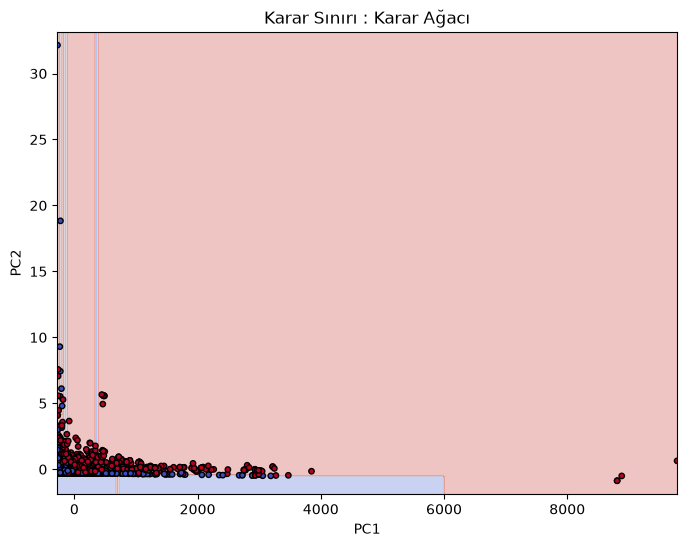

In [14]:
decisionplot(dtree, pd.DataFrame(X_train_pca, columns=['PC1', 'PC2']), y_train)

## Étape 3 : Évaluation du modèle (Model Değerlendirme)

#### Cellule 1 : import des métriques (Değerlendirme metriklerinin içe aktarılması)

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc

#### Cellule 2 : prédiction sur le test (Test verisi üzerinde tahmin)

In [16]:
predictions = dtree.predict(X_test_pca)

print(predictions[:10])
print(y_test.values[:10])

[0 0 0 0 0 0 0 0 0 0]
[0 0 0 1 0 1 0 0 0 0]


#### Cellule 3 : Calculer les métriques (Doğruluk, kesinlik, duyarlılık ve F1 skoru)

In [17]:
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

Accuracy: 0.81
Precision: 0.80
Recall: 0.73
F1 Score: 0.76


#### Cellule 4 : AUC-ROC (AUC-ROC skoru)

In [18]:
# Probabilité que chaque email soit un spam (colonne 1)
y_proba = dtree.predict_proba(X_test_pca)[:, 1]

# Calcul de l'AUC
auc_score = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC: {auc_score:.2f}")

AUC-ROC: 0.77


#### Cellule 5 : Tracer la courbe ROC (ROC eğrisi)

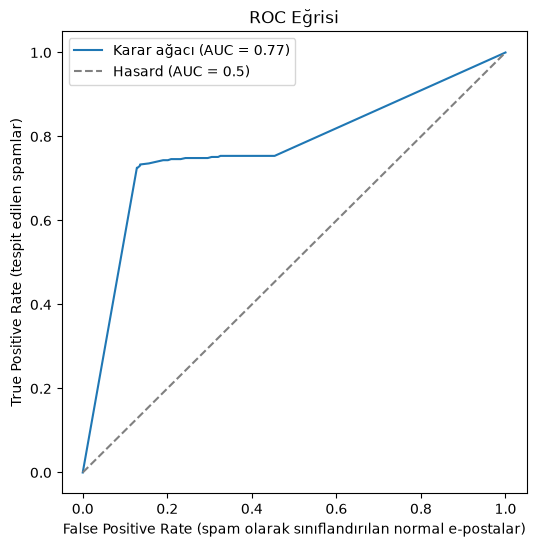

In [19]:
fpr, tpr, seuils = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Karar ağacı (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Hasard (AUC = 0.5)")
plt.xlabel("False Positive Rate (spam olarak sınıflandırılan normal e-postalar)")
plt.ylabel("True Positive Rate (tespit edilen spamlar)")
plt.title("ROC Eğrisi")
plt.legend()
plt.show()